# Table: Bound slope analyses — all blocks, OL and MX

Extends the Panel C and Panel D analyses from Figure 3 to all 6 blocks for both
the OL (online / blocked SNR) and MX (mixed SNR) datasets.

Two analyses, each computed per participant × block:

### 1. Bound ~ DT &nbsp;&nbsp;(Figure 3 Panel C)
Linear regression of |bound| on DT (DT ≥ 2).  
Tests whether inferred bounds grow systematically with decision time.  
**Null**: median slope = 0.

### 2. Δbound ~ bound &nbsp;&nbsp;(Figure 3 Panel D)
Linear regression of Δ|bound|ₜ = |bound|ₜ − |bound|ₜ₋₁ on previous |bound|ₜ₋₁.  
Tests whether large bounds tend to revert toward the mean across consecutive trials.  
Slope = −1 → pure regression to mean; slope = 0 → no systematic trial-to-trial change.  
**Null**: median slope = −1.

---

**Table summary per block**: median [IQR] of per-participant values,
plus Wilcoxon signed-rank p-value (vs. stated null) for each analysis.

**Data**: Both datasets loaded with `combine_snr=False` to retain all 6 raw
block / SNR combinations. Good-trial filter: DT ≥ 2, trial ≥ 10, no wall hit,
no RT below the RT cutoff. Both analyses draw from this same DT ≥ 2 filter.

In [6]:
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

from pigeon.data import get_data_table, get_good_trial_array
from pigeon.path_defaults import FIGURES_DIR
from pigeon.plotting import FONT_RC

In [7]:
# combine_snr=False retains each block as a separate condition rather than
# pooling across SNR levels, giving one row per block in the table.
data_table_ol = get_data_table(task_type='OL', combine_snr=False)
data_table_mx = get_data_table(task_type='MX', combine_snr=False)

BLOCKS = sorted(data_table_ol['block_index'].dropna().unique().astype(int))
print('OL blocks:', BLOCKS)
print('MX blocks:', sorted(data_table_mx['block_index'].dropna().unique().astype(int)))

OL blocks: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MX blocks: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [8]:
def compute_slope_stats(data_table, blocks):
    """
    For each block compute per-subject statistics:
      slopes_c : |bound| ~ DT slopes  (Figure 3 Panel C, DT >= 2)
      slopes_d : Δ|bound| ~ |bound| slopes  (Figure 3 Panel D)

    Both analyses draw from the same base trial set (good-quality trials with a
    valid bound).  A subject is included if they have >= 5 valid data points,
    matching Figure03_boundSummary.ipynb's Panel C/D per-subject inclusion threshold.

    Returns a list of row-dicts (one per block) with median, IQR, Wilcoxon p,
    and participant count n.
    """
    subjects = np.sort(data_table['subject_index'].dropna().unique())
    good     = get_good_trial_array(data_table)
    rows = []

    for block in blocks:
        lg_base = (
            good &
            data_table['bound'].notna() &
            (data_table['block_index'] == block)
        )

        n_subj = sum(
            1 for subj in subjects
            if (lg_base & (data_table['subject_index'] == subj)).sum() >= 5
        )

        slopes_c = []
        slopes_d = []

        for subj in subjects:
            ls = lg_base & (data_table['subject_index'] == subj)

            # ── Analysis 1: |bound| ~ DT (DT >= 2) ──────────────────────────────
            # good/ls already ensures DT >= 2, so no separate DT filter is needed.
            sub_c = data_table[ls]
            if len(sub_c) >= 5:
                dts = sub_c['DT'].to_numpy(dtype=float)
                ab  = np.abs(sub_c['bound'].to_numpy(dtype=float))
                fin = np.isfinite(dts) & np.isfinite(ab)
                if fin.sum() >= 3:
                    try:
                        s, *_ = scipy.stats.linregress(dts[fin], ab[fin])
                        slopes_c.append(s)
                    except ValueError:
                        pass

            # ── Analysis 2: Δ|bound| ~ |bound| ──────────────────────────────────
            # Regress the trial-to-trial change against the PREVIOUS trial's
            # |bound| (not the current one) so that slope = -1 corresponds to
            # classical regression to the mean (matches PigeonSims.m / the
            # generic i.i.d.-noise demo in Figure03S04_sequentialAnalysis.ipynb).
            sub_d = data_table[ls].sort_values('trial_number')
            if len(sub_d) >= 5:
                ab    = np.abs(sub_d['bound'].to_numpy(dtype=float))
                prev  = ab[:-1]
                delta = ab[1:] - prev
                fin   = np.isfinite(prev) & np.isfinite(delta)
                if fin.sum() >= 3:
                    try:
                        s, *_ = scipy.stats.linregress(prev[fin], delta[fin])
                        slopes_d.append(s)
                    except ValueError:
                        pass

        def summarize(slopes, null=0.0):
            arr = np.asarray(slopes, dtype=float)
            if int(np.isfinite(arr).sum()) < 3:
                return dict(median=np.nan, q25=np.nan, q75=np.nan, p=np.nan)
            q25, med, q75 = np.percentile(arr, [25, 50, 75])
            try:
                _, p = scipy.stats.wilcoxon(arr - null)
            except ValueError:
                p = np.nan
            return dict(median=med, q25=q25, q75=q75, p=p)

        sc = summarize(slopes_c, null=0.0)
        sd = summarize(slopes_d, null=-1.0)
        rows.append(dict(
            block=block,
            n=n_subj,
            c_median=sc['median'], c_q25=sc['q25'], c_q75=sc['q75'], c_p=sc['p'],
            d_median=sd['median'], d_q25=sd['q25'], d_q75=sd['q75'], d_p=sd['p'],
        ))

    return rows

In [9]:
rows_ol = compute_slope_stats(data_table_ol, BLOCKS)
rows_mx = compute_slope_stats(data_table_mx, BLOCKS)

Cohort,Block (n),|bound|~DT median [IQR],p (H₀: 0),Δbound~bound median [IQR],p (H₀: −1)
1,1 (55),"0.003 [-0.009, 0.010]",0.441,"-0.969 [-1.071, -0.871]",0.218
1,2 (58),"-0.003 [-0.007, 0.003]",0.042,"-0.970 [-1.072, -0.836]",0.079
1,3 (51),"-0.002 [-0.010, 0.004]",0.131,"-0.979 [-1.071, -0.841]",0.189
1,4 (51),"0.017 [-0.006, 0.051]",0.001,"-1.019 [-1.099, -0.929]",0.482
1,5 (57),"0.003 [-0.010, 0.014]",0.238,"-0.965 [-1.079, -0.895]",0.311
1,6 (51),"0.006 [-0.016, 0.023]",0.165,"-1.105 [-1.213, -0.889]",0.065
2,1 (60),"0.002 [-0.003, 0.011]",0.026,"-0.995 [-1.074, -0.918]",0.941
2,2 (59),"0.002 [-0.004, 0.009]",0.158,"-0.957 [-1.050, -0.867]",0.031
2,3 (52),"-0.002 [-0.009, 0.007]",0.353,"-1.005 [-1.123, -0.840]",0.387
2,4 (54),"0.015 [-0.001, 0.023]",0.000,"-1.007 [-1.107, -0.914]",0.436


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array


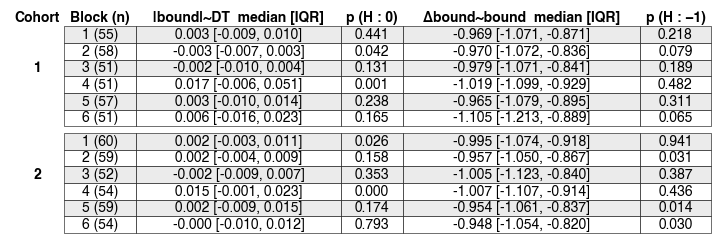

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Table_slopeAnalyses.pdf (+ .png)


In [10]:
def build_table(rows, dataset):
    def fmt_slope(med, q25, q75):
        if np.isnan(med):
            return 'NA'
        return f'{med:.3f} [{q25:.3f}, {q75:.3f}]'

    def fmt_p(p):
        if np.isnan(p):
            return 'NA'
        return f'{p:.3f}'

    records = []
    for r in rows:
        records.append({
            'Cohort':                     dataset,
            'Block (n)':                  f"{r['block']} ({r['n']})",
            '|bound|~DT  median [IQR]':   fmt_slope(r['c_median'], r['c_q25'], r['c_q75']),
            'p (H₀: 0)':                  fmt_p(r['c_p']),
            'Δbound~bound  median [IQR]': fmt_slope(r['d_median'], r['d_q25'], r['d_q75']),
            'p (H₀: −1)':                 fmt_p(r['d_p']),
        })
    return pd.DataFrame(records)


df_ol  = build_table(rows_ol, '1')
df_mx  = build_table(rows_mx, '2')
df_all = pd.concat([df_ol, df_mx], ignore_index=True)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)
display(df_all.style.hide())

# ── Save as PDF/PNG ──────────────────────────────────────────────────────────
# Layout follows the paper's Table 1: the header row is plain (bold text, no
# fill, no border), the Cohort column has no border or shading at all -- just
# the label, centered once per group and bold -- and a thin blank spacer row
# separates the cohorts. Row shading in the data columns alternates within
# each cohort and resets at the boundary. All other text is regular weight,
# Helvetica 12pt (matches FONT_RC's typeface).
#
# macOS's Helvetica.ttc bundles Regular/Bold/Oblique/Bold Oblique as separate
# faces, but matplotlib's font manager only indexes the first (Regular) face
# of a .ttc, so requesting weight='bold' for family='Helvetica' silently
# resolves to the same Regular file -- bold text rendered as regular, and a
# naive workaround (substituting Arial, which matplotlib does expose as a
# separate Bold .ttf) drops glyphs like the ₀ in "H₀" that Arial lacks.
# Instead, pull the real Bold face (index 1) out of the .ttc with fontTools
# so bold cells get genuine Helvetica Bold with full glyph coverage.
import tempfile
from pathlib import Path
from fontTools.ttLib import TTCollection
import matplotlib.font_manager as fm

def _helvetica_bold_fontprops():
    ttc_path = Path('/System/Library/Fonts/Helvetica.ttc')
    if not ttc_path.exists():
        return fm.FontProperties(family='sans-serif', weight='bold')
    bold_face = TTCollection(str(ttc_path)).fonts[1]   # 'Helvetica Bold'
    out_path = Path(tempfile.gettempdir()) / 'HelveticaBold_extracted.ttf'
    bold_face.save(str(out_path))
    return fm.FontProperties(fname=str(out_path))

BOLD_FP = _helvetica_bold_fontprops()

CM = 1 / 2.54
FS = 10
WID = 22   # cm

ROW_GRAY    = (0.92, 0.92, 0.92)   # alternating shaded data row
ROW_WHITE   = (1.00, 1.00, 1.00)   # alternating white data row
THIN_LW     = 0.4                  # inner grid lines
SPACER_FRAC = 0.4                  # spacer-row height, as a fraction of a data row

data_cols = ['Block (n)', '|bound|~DT  median [IQR]', 'p (H₀: 0)',
             'Δbound~bound  median [IQR]', 'p (H₀: −1)']
columns = ['Cohort'] + data_cols
n_cols  = len(columns)

groups = [('1', df_ol), ('2', df_mx)]

# Build cell text plus per-row bookkeeping (cohort group, position within the
# group, and whether the row is a spacer) so cohort merging and the
# inter-cohort gap can be applied after the table is drawn.
cell_text, row_group, row_pos, row_is_spacer = [], [], [], []
for gi, (label, gdf) in enumerate(groups):
    n = len(gdf)
    for i in range(n):
        cell_text.append([''] + [gdf.iloc[i][c] for c in data_cols])
        row_group.append(label)
        row_pos.append((i, n))
        row_is_spacer.append(False)
    if gi < len(groups) - 1:
        cell_text.append([''] * n_cols)
        row_group.append(None)
        row_pos.append(None)
        row_is_spacer.append(True)

plt.rcParams.update(FONT_RC)

fig, ax = plt.subplots(figsize=(WID * CM, 1))   # height adjusted by bbox_inches='tight'
ax.axis('off')

tbl = ax.table(
    cellText=cell_text,
    colLabels=columns,
    cellLoc='center',
    loc='center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(FS)
tbl.auto_set_column_width(col=list(range(n_cols)))

cells = tbl.get_celld()

# matplotlib gives every row the same auto-computed height (sized to fit the
# text at FS); keep that height for normal rows and only shrink the spacer.
base_h = cells[(1, 0)].get_height()

def _make_bold(text_obj):
    text_obj.set_fontproperties(BOLD_FP)
    text_obj.set_fontsize(FS)

for (row, col), cell in cells.items():
    if row == 0:
        # header: bold text only, no fill, no border
        cell.set_facecolor('white')
        cell.set_linewidth(0)
        cell.visible_edges = ''
        _make_bold(cell.get_text())
        continue

    label = row_group[row - 1]
    if label is None:
        # spacer row: blank gap between cohorts
        cell.set_facecolor('white')
        cell.set_linewidth(0)
        cell.visible_edges = ''
        continue

    idx, size = row_pos[row - 1]

    if col == 0:
        # cohort label: no border, no shading -- just the bold text,
        # centered vertically within the group
        cell.set_facecolor('white')
        cell.set_linewidth(0)
        cell.visible_edges = ''
        cell.get_text().set_text(label if idx == (size - 1) // 2 else '')
        _make_bold(cell.get_text())
    else:
        cell.set_facecolor(ROW_GRAY if idx % 2 == 0 else ROW_WHITE)
        cell.set_linewidth(THIN_LW)

# Shrink the spacer row and shift every row below it up to close the gap,
# starting from the bottom edge of the header (whose position is untouched).
y_cursor = cells[(0, 0)].get_y()
for r in range(1, len(row_group) + 1):
    h = base_h * SPACER_FRAC if row_is_spacer[r - 1] else base_h
    y_cursor -= h
    for c in range(n_cols):
        cells[(r, c)].set_y(y_cursor)
        cells[(r, c)].set_height(h)

out = FIGURES_DIR / 'Table_slopeAnalyses.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')